To be run in `imagery` env

In [ ]:
import sys
import numpy as np
sys.path.append("/Users/hyin/soft/insar_surface-def_tools/ffm2los/")
import cutde_utils as cutde
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
# solfile = '/Users/hyin/soft/insar_surface-def_tools/ffm2los/Solution_test_normal.txt'
solfile = '/Users/hyin/usgs_mendenhall/events/20261009_panama/ffm/20261017/NP1.16/Solution.txt'

cutde_sources = cutde.read_solution_sources(solfile)
# cutde_sources.tris

In [ ]:
## Single point test

# lat, lon = 7.44796,-80.64623
# disp = cutde.surface_displacement(cutde_sources, lon, lat, nu=0.25, max_pairs=2_000_000)
# print(f"Displacements E: {disp[0]}m, N: {disp[1]}m, U: {disp[2]}m,")

Displacements E: -2.418791979490857m, N: 0.7940388818684679m, U: -0.44443199617199264m,


In [14]:
# Try a grid
lon, lat, geotransform = cutde.grid_around(cutde_sources, pad_km=10, res=0.005)
u = cutde.surface_displacement(cutde_sources, lon, lat)      # (ny, nx, 3)
bands = np.moveaxis(u, -1, 0)                # (3, ny, nx)

In [15]:
import numpy as np
import rasterio
from rasterio.transform import Affine

bands = np.moveaxis(u, -1, 0).astype("float32")      # (ny, nx, 3) -> (3, ny, nx)
_, ny, nx = bands.shape
band_names = ["East displacement (m)", "North displacement (m)", "Up displacement (m)"]

with rasterio.open(
    "displacement.tif", "w", driver="GTiff",
    height=ny, width=nx, count=3, dtype="float32",
    crs="EPSG:4326", transform=Affine.from_gdal(*geotransform),
    compress="deflate",
) as f:
    f.write(bands)
    for i, name in enumerate(band_names, start=1):
        f.set_band_description(i, name)               # band name shown in QGIS / gdalinfo
        f.update_tags(i, units="m")                   # units tag on each band
    f.update_tags(units="m")                          # and on the file

## Plot the results

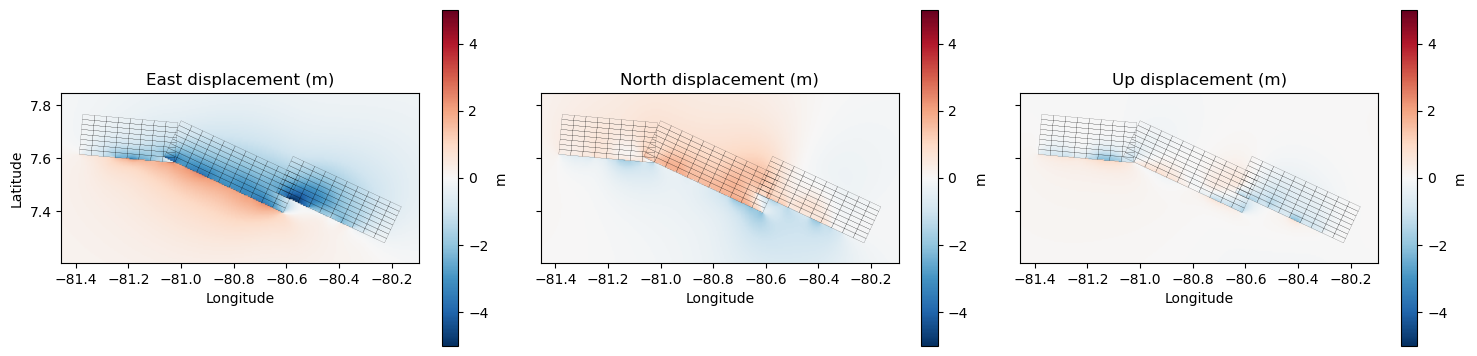

In [22]:
import numpy as np
import matplotlib.pyplot as plt

vmax = 5
# --- raster extent from the geotransform (pixel edges, north-up) ---
ny, nx = lon.shape
west, north = geotransform[0], geotransform[3]
east, south = west + nx * geotransform[1], north + ny * geotransform[5]

src = cutde_sources

# --- fault footprint: surface projection of each subfault rectangle ---
n_sub = len(src.centers)
corners = np.concatenate([src.tris[:n_sub], src.tris[n_sub:, 2:3]], axis=1)       # (N, 4, 3): the 4 corners of each subfault
fx, fy = src.to_lonlat(corners[:, :, 0].ravel(), corners[:, :, 1].ravel())
fx, fy = fx.reshape(-1, 4), fy.reshape(-1, 4)

# --- three panels: East, North, Up ---
titles = ["East displacement (m)", "North displacement (m)", "Up displacement (m)"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
for i, (ax, title) in enumerate(zip(axes, titles)):
    comp = u[:, :, i]
    im = ax.imshow(comp, extent=[west, east, south, north], origin="upper",
                   cmap="RdBu_r", vmin=-vmax, vmax=vmax)         # red = positive (east / north / up)
    for k in range(n_sub):
        ax.plot(np.append(fx[k], fx[k, 0]), np.append(fy[k], fy[k, 0]), color="k", lw=0.1)
    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_aspect(1 / np.cos(np.radians(lat.mean())))            # so 1 km looks the same in x and y
    fig.colorbar(im, ax=ax, shrink=0.8, label="m")
axes[0].set_ylabel("Latitude")
plt.tight_layout()
plt.savefig("displacement.png", dpi=200)
plt.show()